# 19F 化学位移预测

根据分子结构预测 19F 化学位移。利用返回的原子编号，可以把预测值标到分子结构上，也可以与实测峰比较。

使用固态 NMRNet 权重，为准备好的分子构象生成逐原子 F/P 预测。基准将保存的预测与严格配对的 LMDB 标签计分；调用时指定冻结推理目录，并选择跨数据域比较选项。

本教程读取保存的预测，解释输入输出字段，并评估结果。最后给出在新数据集上运行模型的命令。

In [1]:
import json, sys, io
from pathlib import Path
from IPython.display import display, Markdown, SVG
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'openmolspec_bench').is_dir()), None)
if root is None:
    raise RuntimeError('Run from the cloned release repository; see Quick Start')
sys.path.insert(0, str(root / 'scripts'))
from documentation_evidence import load_evidence, compact, recompute, render
from documentation_content import results_table
evidence = load_evidence('nmr.forward.19F')
print('Task:', evidence['task'])
print('Examples:', len(evidence['examples']))

Task: nmr.forward.19F
Examples: 3


## 输入与输出

| Field | Meaning |
| --- | --- |
| `smiles / geometry` | 有效分子结构及相容的三维构象，必须保留原子顺序。 |
| `nucleus` | 19F，权重必须覆盖该核种。 |
| `reference peaks` | 评测时提供实测 ppm 标签；标签不作为模型推理输入。 |

| Field | Meaning |
| --- | --- |
| `prediction_ppm` | 逐原子化学位移（ppm）及原子编号，或整理后的峰列表。 |
| `error / coverage` | 与参考谱匹配后的误差及峰覆盖率。 |

查看下面的示例记录。长数组显示长度与前几个数值，下载 JSON 可获取完整数组。

In [2]:
for example in evidence['examples'][:3]:
    print(json.dumps(compact(example), indent=2, ensure_ascii=False))

{
  "input": {
    "smiles": "CCC(C)NC(=O)/C(F)=C(\\c1ccccc1)C(C)C(=O)OCC",
    "nucleus": "F",
    "atom_indices": [
      8
    ]
  },
  "output": {
    "prediction_ppm": 262.4828796386719
  },
  "reference": {
    "ppm": -121.01998138427734
  }
}
{
  "input": {
    "smiles": "CC(C)OC1(c2ccc(F)cc2)CCCCC1",
    "nucleus": "F",
    "atom_indices": [
      9
    ]
  },
  "output": {
    "prediction_ppm": 254.3622283935547
  },
  "reference": {
    "ppm": -116.1999740600586
  }
}
{
  "input": {
    "smiles": "CC(=O)C(F)S(=O)(=O)c1ccccc1",
    "nucleus": "F",
    "atom_indices": [
      4
    ]
  },
  "output": {
    "prediction_ppm": 303.3087158203125
  },
  "reference": {
    "ppm": -179.58999633789062
  }
}


## 评估预测

MAE 和 RMSE 的单位均为 ppm。

表格给出每次运行的数据集与指标。后续代码从绘图使用的预测值重新计算汇总结果。

In [3]:
display(Markdown(results_table(evidence, False)))
print(json.dumps(recompute(evidence), indent=2, ensure_ascii=False))

| Dataset / scope | Model / variant | Metric | Value |
| --- | --- | --- | ---: |
| recorded evaluation | recorded model | mae_ppm | 356.345 |
| recorded evaluation | recorded model | rmse_ppm | 364.396 |
| recorded evaluation | recorded model | examples | 32 |


{
  "paired_values": 32,
  "mae": 356.34472984075546,
  "rmse": 364.3964037406484,
  "unit": "ppm"
}


## 查看结果图

预测值与参考值。

比较预测与参考，查看返回的结构或峰位置。图由上方读取的记录直接生成。

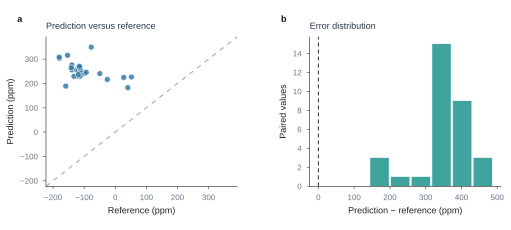

In [4]:
import matplotlib.pyplot as plt
for example_index in range(1):
    figure = render('nmr.forward.19F', evidence, example_index=example_index)
    image = io.StringIO()
    figure.savefig(image, format='svg', metadata={'Date': None})
    display(SVG(image.getvalue()))
    plt.close(figure)

## 运行模型

按任务指南配置环境和权重，在 benchmark runner 中选择本任务，即可评估自己的数据集。

```bash
python -m openmolspec_bench run --workspace /path/to/OpenMolSpec \
  --tasks nmr.forward.19F --fp-inference-root /path/to/frozen-fp --allow-cross-domain-diagnostic --limit 8 --output results/nmr-forward-19F.json
```

[Task](../tasks/nmr-forward-19F.md) · [Quick start](../quickstart.md)



## 参考文献

- Xu, F., Guo, W., Wang, F., Yao, L., Wang, H., Tang, F., Gao, Z., Zhang, L., E, W., Tian, Z.-Q., et al. Toward a unified benchmark and framework for deep learning-based prediction of nuclear magnetic resonance chemical shifts. Nature Computational Science 5, 292–300 (2025). doi:10.1038/s43588-025-00783-z. [Source](https://doi.org/10.1038/s43588-025-00783-z)
- OpenDataLab. WanJuan MolSpectra, version 1.0.3. Experimental molecular spectroscopy dataset. [Source](https://opendatalab.com/)
